In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
%pip install langchain langchain-core langchain-openai langchain-anthropic -q
import os
if os.path.exists("requirements.txt"):
    %pip install -r requirements.txt -q
else:
    print("requirements.txt not found -- skipping")


In [ ]:
%pip install langchain-ollama -q

In [ ]:
# ======================================================================
# COMPANY PROFILE -- the only company-specific part of this notebook.
# The analysts, debate, trader, risk and verifier code is shared by every international notebook: raem_analysts/international/
# To change a company-specific value (ticker, log name, peer list, sector text), edit it here.
# ======================================================================
COMPANY = "0300.HK"
RAEM_PROFILE = {
    "group": "international",
    "TICKER": "0300.HK",
    "LOG": "MIDEA",
    "FILE": "0300_HK",
    "slots": {
        "graph_analyst.1": [
            "    # Hong Kong large / liquid names (symbols from memory; any that return <60 rows are dropped automatically)",
            "    \"0700.HK\", \"9988.HK\", \"3690.HK\", \"1810.HK\", \"9618.HK\", \"9999.HK\", \"1024.HK\", \"0981.HK\", \"0992.HK\", \"2382.HK\",",
            "    \"0005.HK\", \"1299.HK\", \"2318.HK\", \"0388.HK\", \"1398.HK\", \"3988.HK\", \"0939.HK\", \"2388.HK\",",
            "    \"0883.HK\", \"0857.HK\", \"0386.HK\", \"0941.HK\", \"0728.HK\", \"0762.HK\", \"0688.HK\", \"0016.HK\", \"1113.HK\", \"0001.HK\",",
            "    \"0002.HK\", \"0003.HK\", \"0006.HK\", \"0012.HK\", \"0267.HK\", \"0175.HK\", \"1211.HK\", \"2020.HK\", \"2331.HK\", \"6690.HK\", \"0968.HK\",",
            "    \"0300.HK\", \"2269.HK\", \"1177.HK\", \"1093.HK\", \"0291.HK\", \"0027.HK\", \"1928.HK\","
        ],
        "forecasting_agent.1": [
            "#   4) Writes every candidate's h=1..10 predictions to forecast_log/0300.HK_forecasts.csv (same schema as AAPL_forecasts.csv)"
        ]
    }
}

import os, sys
sys.path.insert(0, os.getcwd())   # raem_analysts/ sits next to the notebooks
from raem_analysts import use_shared

In [ ]:
# Llm Setup And Logger -- shared code: raem_analysts/international/llm_setup_and_logger.py
use_shared("llm_setup_and_logger")

In [ ]:
import sys, os

# TradingAgents is vendored next to this folder, in ../TradingAgents-main.
# To use a checkout somewhere else, set the TRADINGAGENTS_PATH environment
# variable before starting Jupyter -- it is tried first.
_candidates = [
    os.environ.get("TRADINGAGENTS_PATH", ""),
    os.path.abspath(os.path.join(os.getcwd(), "..", "TradingAgents-main")),
    os.path.abspath(os.path.join(os.getcwd(), "TradingAgents-main")),
    os.path.abspath(os.path.join(os.getcwd(), "TradingAgents")),
]
TRADING_AGENTS_PATH = next(
    (p for p in _candidates if p and os.path.isdir(os.path.join(p, "tradingagents"))),
    _candidates[1],
)

if TRADING_AGENTS_PATH not in sys.path:
    sys.path.insert(0, TRADING_AGENTS_PATH)

if not os.path.isdir(os.path.join(TRADING_AGENTS_PATH, "tradingagents")):
    print(f"⚠️  TradingAgents not found at: {TRADING_AGENTS_PATH}")
    print("    Set the TRADINGAGENTS_PATH environment variable to your TradingAgents checkout.")
else:
    print("✅ Path added:", TRADING_AGENTS_PATH)


## 🧠 ChromaDB Memory Setup (RAEM Episodic Memory + News RAG)

In [ ]:
# Chromadb Memory Setup -- shared code: raem_analysts/international/chromadb_memory_setup.py
use_shared("chromadb_memory_setup")

## 📈 Outcome Backfill — পুরোনো PENDING episodes-এ আজকের price দিয়ে P&L আপডেট

In [ ]:
# Outcome Backfill -- shared code: raem_analysts/international/outcome_backfill.py
use_shared("outcome_backfill")

In [ ]:
import os
os.environ["TRADINGAGENTS_LLM_PROVIDER"] = "ollama"
print("✅ Config ready!")

## 📡 Market-data shim (yfinance) for the v11 price-based cells

The v11 cells (10-day scenario, peer-graph analyst, forecasting agent, position sizing) were written for the DSE and call
`fetch_dse_ohlcv_range()` / `fetch_dse_company_snapshot()`. This notebook trades a yfinance ticker, so the same two names are
defined here on top of yfinance and return the same shapes (Date-indexed Open/High/Low/Close/Volume, ascending; `{"Sector": ...}`).
Nothing else in the v11 cells needed to change.

In [ ]:
# Market Data Shim -- shared code: raem_analysts/international/market_data_shim.py
use_shared("market_data_shim")

## 🛡️ Fact Guard — handoff-level hallucination check on every LLM call

Each agent's output is checked in code before the next agent reads it: numbers must come from the agent's own input, and known label/direction errors (SMA support vs resistance, N/A cited as 0%, TTM mislabel, missing data read as neutral) trigger one re-ask. Set `GUARD_ENABLED = False` to turn it off.

In [ ]:
# Fact Guard -- shared code: raem_analysts/international/fact_guard.py
use_shared("fact_guard")

In [ ]:
# Fundamentals Analyst -- shared code: raem_analysts/international/fundamentals_analyst.py
use_shared("fundamentals_analyst")

In [ ]:
# Market Analyst -- shared code: raem_analysts/international/market_analyst.py
use_shared("market_analyst")

## 🌍 Macro Regime Analyst — Market-Wide Risk Regime (VIX / Yields / DXY)

In [ ]:
# Macro Regime Analyst -- shared code: raem_analysts/international/macro_regime_analyst.py
use_shared("macro_regime_analyst")

In [ ]:
# News Analyst -- shared code: raem_analysts/international/news_analyst.py
use_shared("news_analyst")

## 📰 News RAG — Chunk & Store in ChromaDB

In [ ]:
# News Rag -- shared code: raem_analysts/international/news_rag.py
use_shared("news_rag")

In [ ]:
# Sentiment Analyst -- shared code: raem_analysts/international/sentiment_analyst.py
use_shared("sentiment_analyst")

## 🕸️ Graph Analyst — Peer Graph + GAT (adapted from BlindTrade)

Builds a sector + correlation graph over DSE peers, computes neighbor-aggregated features for the target stock, and trains a small GAT walk-forward. The GAT score is passed to the debaters **only if its holdout rank-IC > 0** (validate-before-deploy). Output `graph_context` is picked up by `format_hard_indicators()` in the next cell.

In [ ]:
# Graph Analyst -- shared code: raem_analysts/international/graph_analyst.py
use_shared("graph_analyst")

## 🕸️ Graph-linked news + peer-graph retrieval
Rule-based knowledge graph over `news_corpus` (NEWS → TICKER / TOPIC / REG edges). Uses `graph_result` peers, adds sector / regulator / macro news (tariffs, Fed, OPEC, antitrust...) and peers' news to `news_rag_context`. Switch: `USE_NEWS_GRAPH`.

## 👥🧬 Graph-RAG extensions (v4)
Two cells run **before** the news-graph cell: (1) peer-stock price episodes (regime → forward return) stored in `episodic_memory`, so the peer-episode hop has data; (2) LLM entity/relation extraction (Qwen2.5:7b, JSON mode, grounded in code, disk-cached) that adds entity/relation edges to the news graph. Ablation switches: `USE_PEER_EPISODES`, `USE_LLM_GRAPH`.

In [ ]:
# Peer Episodes -- shared code: raem_analysts/international/peer_episodes.py
use_shared("peer_episodes")

In [ ]:
# Llm Graph Extraction -- shared code: raem_analysts/international/llm_graph_extraction.py
use_shared("llm_graph_extraction")

In [ ]:
# Graph News -- shared code: raem_analysts/international/graph_news.py
use_shared("graph_news")

## 🔮 Forecasting Agent (validated 10-day price forecast)

Code-only agent: purged walk-forward validation of naive / damped-trend / ridge / analog-kNN. A model is used only if it beats the naive baseline on a holdout (MAE, t-stat, direction gate); otherwise the agent reports **no forecast skill** and only a historical-error range. Result is injected into the FACT SHEET and logged to `forecast_log/0300.HK_forecasts.csv` (same schema as the other forecast logs).

In [ ]:
# Forecasting Agent -- shared code: raem_analysts/international/forecasting_agent.py
use_shared("forecasting_agent")

In [ ]:
# Hard Data Helper -- shared code: raem_analysts/international/hard_data_helper.py
use_shared("hard_data_helper")

In [ ]:
# Bear Researcher -- shared code: raem_analysts/international/bear_researcher.py
use_shared("bear_researcher")

In [ ]:
# Bull Researcher -- shared code: raem_analysts/international/bull_researcher.py
use_shared("bull_researcher")

In [ ]:
# Investment Facilitator -- shared code: raem_analysts/international/investment_facilitator.py
use_shared("investment_facilitator")

In [ ]:
# Investment Debate Facilitator -- shared code: raem_analysts/international/investment_debate_facilitator.py
use_shared("investment_debate_facilitator")

## 🔁 Retrieve Similar Past Episodes (for Trader memory injection)

## 🔄 Regime-Transition Reflection — regime বদলালে আগের regime থেকে শেখা

In [ ]:
# Regime Transition Reflection -- shared code: raem_analysts/international/regime_transition_reflection.py
use_shared("regime_transition_reflection")

## 🧾 Post-Mortem / Self-Critique Agent — Cross-Regime Lessons Learned

In [ ]:
# Post Mortem Agent -- shared code: raem_analysts/international/post_mortem_agent.py
use_shared("post_mortem_agent")

## 🕸️ Graph Memory — graph-RAG over episodic memory


In [ ]:
# Graph Memory -- shared code: raem_analysts/international/graph_memory.py
use_shared("graph_memory")

In [ ]:
# Retrieve Past Episodes -- shared code: raem_analysts/international/retrieve_past_episodes.py
use_shared("retrieve_past_episodes")

In [ ]:
# Trader -- shared code: raem_analysts/international/trader.py
use_shared("trader")

In [ ]:
# Aggressive Debator -- shared code: raem_analysts/international/aggressive_debator.py
use_shared("aggressive_debator")

In [ ]:
# Conservative Debator -- shared code: raem_analysts/international/conservative_debator.py
use_shared("conservative_debator")

In [ ]:
# Neutral Debator -- shared code: raem_analysts/international/neutral_debator.py
use_shared("neutral_debator")

In [ ]:
# Risk Debate -- shared code: raem_analysts/international/risk_debate.py
use_shared("risk_debate")

In [ ]:
# Risk Facilitator -- shared code: raem_analysts/international/risk_facilitator.py
use_shared("risk_facilitator")

In [ ]:
# Portfolio Manager -- shared code: raem_analysts/international/portfolio_manager.py
use_shared("portfolio_manager")

In [ ]:
# Portfolio Manager Decision -- shared code: raem_analysts/international/portfolio_manager_decision.py
use_shared("portfolio_manager_decision")

## 📈 Prediction Engine — Quantitative 5-Day Price Forecast


In [ ]:
# Prediction Engine -- shared code: raem_analysts/international/prediction_engine.py
use_shared("prediction_engine")

In [ ]:
# Forecast Graph -- shared code: raem_analysts/international/forecast_graph.py
use_shared("forecast_graph")

## 🔍 Decision Verifier / Fact-Check Agent — Post-Decision Recheck

In [ ]:
# Decision Verifier -- shared code: raem_analysts/international/decision_verifier.py
use_shared("decision_verifier")

## 📈 10-Day Scenario Estimate — if you buy today, what range of gain/loss could 10 trading days bring?

For every day in the last 12 months of daily closes: `10-day return % = (close 10 trading days later / close that day − 1) × 100`. The percentiles of those ~230 returns (worst 5% … best 5%) are applied to your buy price, with an assumed round-trip cost, and the chance of a gain is counted.

Set `SCEN_BUY_PRICE`, `SCEN_SHARES` and `SCEN_COST_PCT` at the top of the next cell. It is the **historical range** of outcomes, **not a forecast** and not investment advice. Skips quietly if the price fetch fails.

In [ ]:
# Scenario Estimate -- shared code: raem_analysts/international/scenario_estimate.py
use_shared("scenario_estimate")

## 💾 Save Episode to ChromaDB Memory

In [ ]:
# Save Episode -- shared code: raem_analysts/international/save_episode.py
use_shared("save_episode")

In [ ]:
# Trading Log View -- shared code: raem_analysts/international/trading_log_view.py
use_shared("trading_log_view")

In [ ]:
# Comparison Backtest -- shared code: raem_analysts/international/comparison_backtest.py
use_shared("comparison_backtest")

## 📈 7-Day Forecast & Hit Rate (standalone)

This section runs **on its own**: no Ollama and none of the agent cells above are needed. After a kernel restart you can run just the cell below.

It trains 14 base models:

- **Originals:** Ridge, XGBoost, LSTM, ARIMA, Kalman.
- **From the papers in `paper/`:** LASSO (Iworiso 2023), Random Forest and DNN (Krauss et al. 2016), WSAE-LSTM (Bao et al. 2017), N-BEATS (Oreshkin et al. 2020).
- **Also added:** regime switching, ARIMAX, a Temporal Fusion Transformer (TFT), and the Theta method.

On top of these sit two **fusion** models, which learn for this ticker how to combine the base models:

- **Fusion:** learned non-negative weights, with "no change" as one of the options.
- **Fusion-Top3:** the 3 lowest-error models, each weighted by 1/error.

The **Ensemble** is the average of the **best two** base models for this ticker, meaning the two with the lowest error on past holdout dates. The main chart draws **every** model's path. A second chart gives each model its own panel, and the table lists every model's forecast and its error against "no change".

During **Run All**, this cell reuses the forecast already trained by the *7-DAY FORECAST GRAPH* cell above instead of training everything twice.

**Fusion check table:** this is the fair comparison. Each pick (best two, fusion weights, top 3) is made on the earlier holdout dates. Then every model, the Ensemble, both fusions, the mean of all models and "no change" are scored on later dates that the picks never saw. A `mae_vs_naive` below 1 beats "no change".

Every run saves today's 7-day forecast to `forecast_log/`. It then grades every earlier forecast whose target date has arrived. The **hit rate** is measured two ways:

- **Within ±1%**: the predicted price landed within 1% of the actual close on that day.
- **Direction right**: the forecast said up or down from the price when it was made, and the price went that way. "No change" forecasts don't count either way.

A direction hit rate only means something if it beats **always predicting UP**, because stocks drift, so that baseline is shown next to it. The **p-value** says whether the day-7 calls beat a coin flip by more than luck; under 0.05 means they do. Past forecasts include walk-forward replays, each trained only on data available on that date.

  0300.HK: already current (last row 2026-10-02)
0300.HK (Midea Group): 493 rows (493 snapshot + 0 daily-log), 2024-10-02 to 2026-10-02
  training 14 multi-step models on 437 labeled rows ...


Graded 0 past prediction(s) whose target date has now arrived.


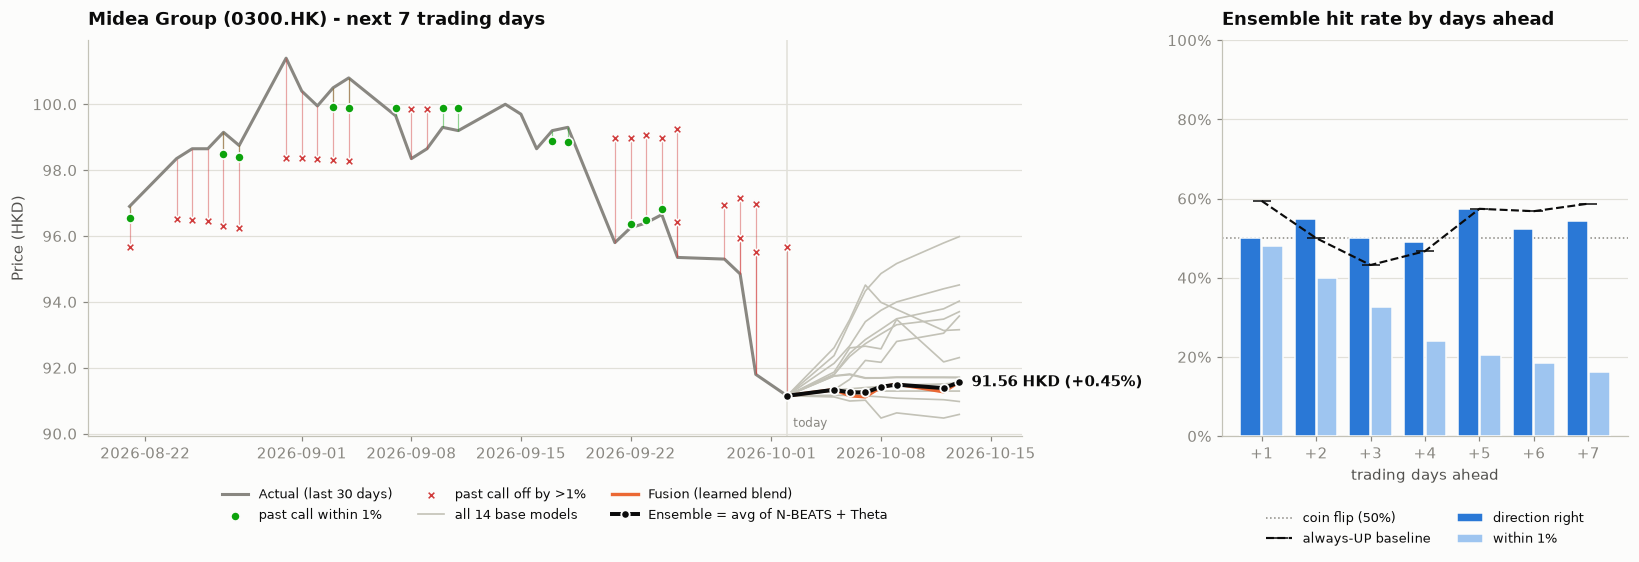

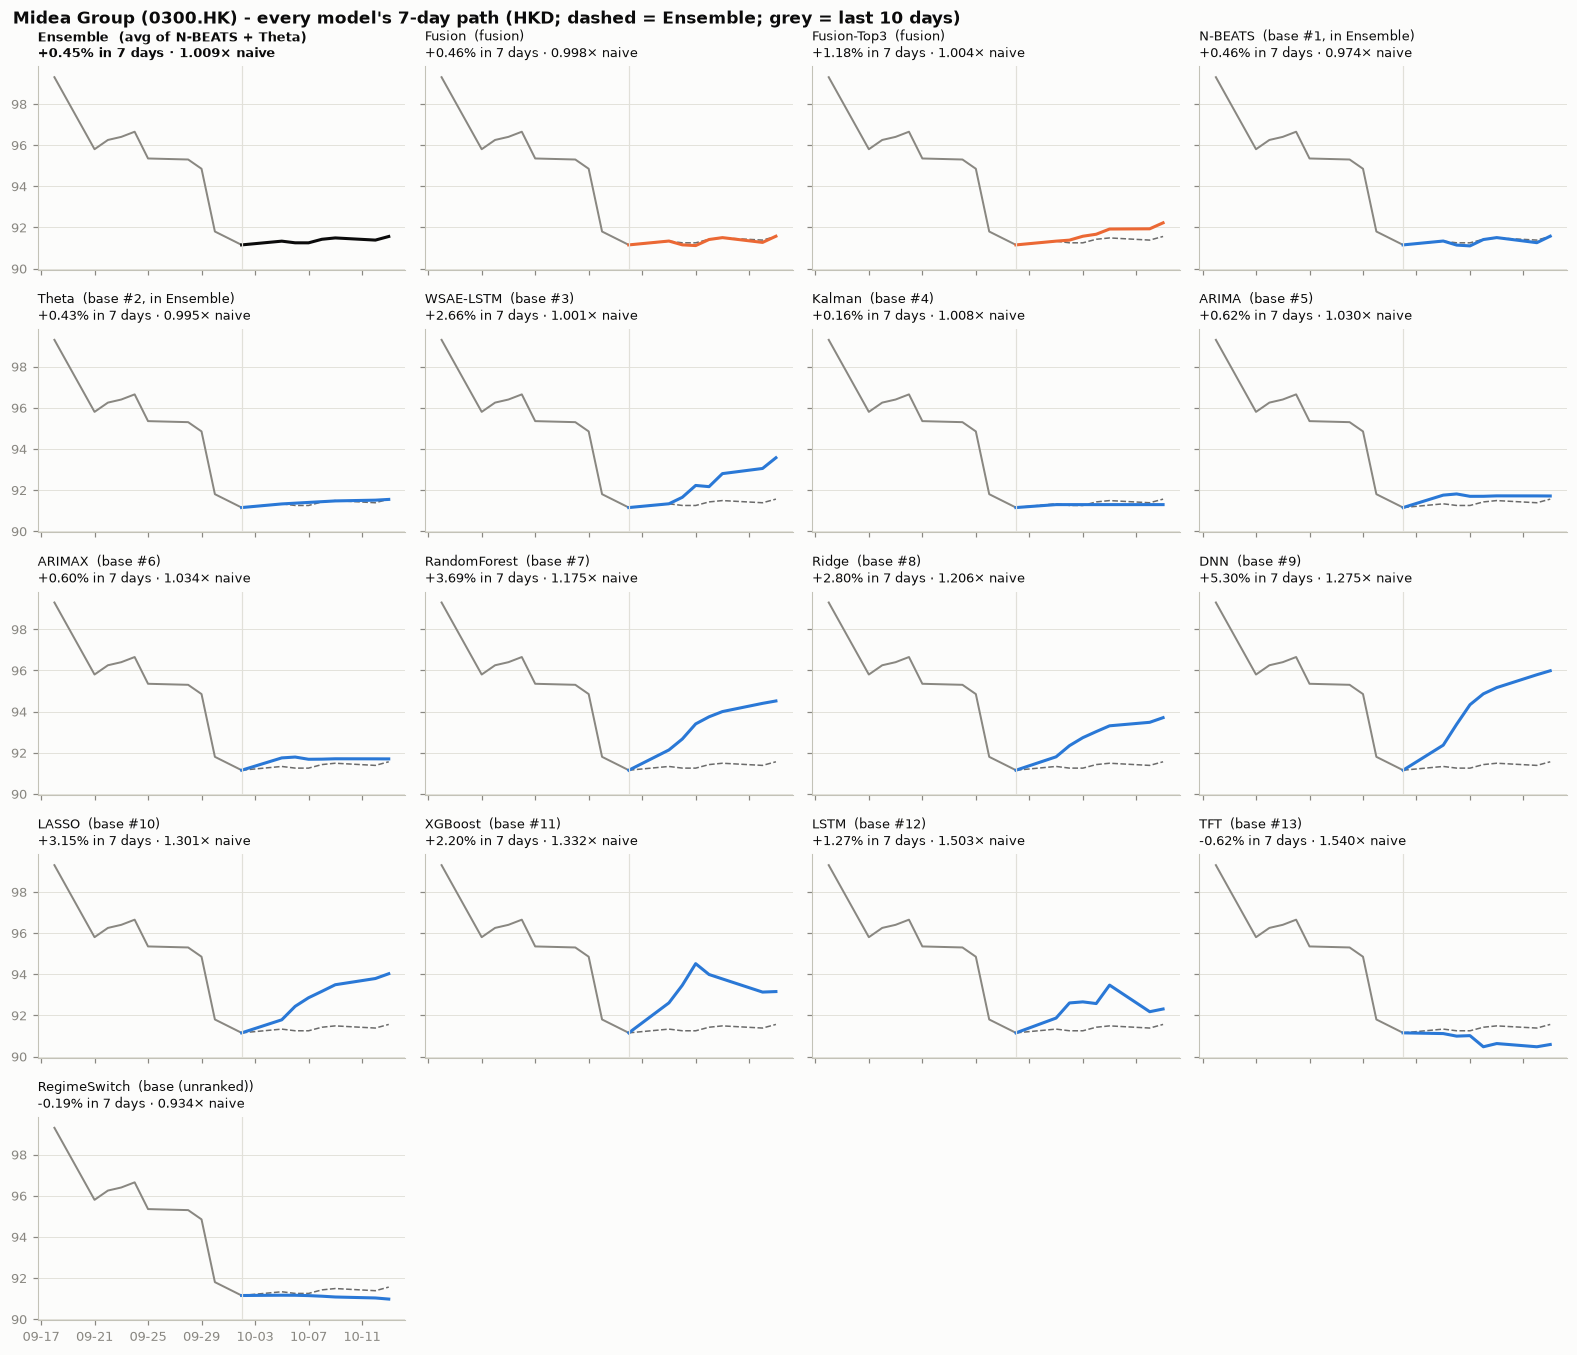

Ensemble = average of the best two models: N-BEATS + Theta
Every model's 7-day forecast (HKD); error_vs_naive < 1 beats 'no change':


,role,day1_HKD,day7_HKD,move_7d_%,error_vs_naive,scored_on,holdout_direction_acc
model,,,,,,,
Ensemble,avg of N-BEATS + Theta,91.3325,91.5596,0.45,1.009,unseen test dates,0.502
Fusion,fusion,91.3380,91.5720,0.46,0.998,unseen test dates,0.576
Fusion-Top3,fusion,91.3329,92.2227,1.18,1.004,unseen test dates,0.532
N-BEATS,"base #1, in Ensemble",91.3386,91.5734,0.46,0.974,common holdout,0.524
Theta,"base #2, in Ensemble",91.3264,91.5458,0.43,0.995,common holdout,0.522
WSAE-LSTM,base #3,91.3336,93.5702,2.66,1.001,common holdout,0.530
Kalman,base #4,91.2933,91.2933,0.16,1.008,common holdout,0.471
ARIMA,base #5,91.7539,91.7123,0.62,1.030,common holdout,0.477
ARIMAX,base #6,91.7482,91.6994,0.60,1.034,common holdout,0.442


Predicted price by day, every model:


,Ridge,XGBoost,LSTM,ARIMA,Kalman,LASSO,RandomForest,DNN,WSAE-LSTM,TFT,Theta,N-BEATS,RegimeSwitch,ARIMAX,Ensemble,Fusion,Fusion-Top3
date,,,,,,,,,,,,,,,,,
2026-10-05,91.80,92.61,91.87,91.75,91.29,91.78,92.13,92.37,91.33,91.12,91.33,91.34,91.16,91.75,91.33,91.34,91.33
2026-10-06,92.34,93.46,92.60,91.81,91.29,92.44,92.67,93.38,91.65,90.99,91.36,91.14,91.16,91.79,91.25,91.15,91.38
2026-10-07,92.73,94.51,92.66,91.70,91.29,92.86,93.40,94.33,92.22,91.02,91.40,91.10,91.15,91.68,91.25,91.12,91.57
2026-10-08,93.03,93.99,92.57,91.70,91.29,93.17,93.75,94.86,92.17,90.47,91.44,91.41,91.12,91.69,91.42,91.41,91.67
2026-10-09,93.31,93.77,93.47,91.72,91.29,93.49,94.00,95.17,92.80,90.63,91.47,91.51,91.08,91.71,91.49,91.50,91.92
2026-10-12,93.48,93.13,92.18,91.72,91.29,93.79,94.40,95.79,93.05,90.47,91.51,91.26,91.03,91.70,91.38,91.27,91.93
2026-10-13,93.70,93.16,92.31,91.71,91.29,94.02,94.51,95.98,93.57,90.58,91.55,91.57,90.98,91.70,91.56,91.57,92.22


Holdout scoreboard -- every base model on the last 15% of history (mae_vs_naive < 1 beats 'no change'; always-UP would score 63.0% direction):


...

Ensemble, by days ahead:


,graded_calls,hit_within_1pct_%,mean_abs_error_%,direction_calls,direction_hit_%,always_up_%
days_ahead,,,,,,
1,50,48.0,1.20,32,50.0,59.4
2,50,40.0,1.68,42,54.8,50.0
3,49,32.7,1.89,44,50.0,43.2
4,50,24.0,2.40,45,48.9,46.7
5,49,20.4,2.69,47,57.4,57.4
6,49,18.4,2.80,44,52.3,56.8
7,49,16.3,2.95,46,54.3,58.7


Most recent graded Ensemble calls:


,made_on,target_date,days_ahead,price_then,predicted,actual,error_%,within_1pct,direction
0,2026-09-21,2026-09-24,3,95.80,96.82,96.65,0.17,HIT,right
1,2026-09-16,2026-09-24,6,98.65,98.98,96.65,2.41,miss,wrong
2,2026-09-21,2026-09-25,4,95.80,96.42,95.35,1.13,miss,wrong
3,2026-09-16,2026-09-25,7,98.65,99.25,95.35,4.09,miss,wrong
4,2026-09-21,2026-09-28,5,95.80,96.93,95.30,1.71,miss,wrong
5,2026-09-28,2026-09-29,1,95.30,95.95,94.85,1.16,miss,wrong
6,2026-09-21,2026-09-29,6,95.80,97.15,94.85,2.42,miss,wrong
7,2026-09-28,2026-09-30,2,95.30,95.52,91.80,4.06,miss,wrong
8,2026-09-21,2026-09-30,7,95.80,96.97,91.80,5.63,miss,wrong
9,2026-09-28,2026-10-02,4,95.30,95.68,91.15,4.96,miss,wrong


137 call(s) still waiting for their target date (next one: 2026-10-05); 6 fell on a holiday or missing day and can never be graded.


In [1]:
# Forecast Hit Rate -- shared code: raem_analysts/international/forecast_hit_rate.py
use_shared("forecast_hit_rate")

## 🔮🧐 7-Day Price Forecast Agent + Reviewer Agent (standalone)

Two code-only agents (no Ollama, no earlier cell needed) that sit on top of the 7-day models above and give one answer to *"what will the price be over the next 7 trading days?"*.

**Forecast agent** — takes every base model's error on the common out-of-sample holdout dates, picks the **3 best models for this ticker**, and averages their day+1 ... day+7 paths into one forecast.

**Reviewer agent** — audits that forecast. When a check fails it **changes the forecast** and says what it changed:

- **Data freshness** — warns if the last price is old (the forecast would start from a stale price).
- **Path integrity** — a member with NaN or non-positive prices is replaced by the next best model.
- **Members beat naive** — a member that does not beat "no change" on the holdout is swapped for a better one.
- **Direction agreement** — warns when the 3 models disagree on up/down.
- **Calibration** — if the average is over-confident on the holdout, every move is scaled toward "no change" (only if that cuts the holdout error by 2% or more).
- **Plausible range** — a move bigger than the 95th percentile of past same-horizon moves is clipped.
- **Price band** — a 10-90% range from the models' own holdout errors.
- **Live track record** — the graded hit rate from `forecast_log/`, for context.

The result is a day-by-day price table (the 3 members, the reviewed forecast, low/high), a chart, and a confidence label (HIGH / MEDIUM / LOW). During **Run All** it reuses the forecast trained earlier; run on its own it trains the models first (~2 min). The logic lives in `forecast_agent.py` in the project root.

This is a statistical forecast, not advice: the fusion check table above shows how little most models beat "no change", and LOW confidence means exactly that.

In [ ]:
# ================================================================
# 7-DAY FORECAST AGENT + REVIEWER AGENT -- standalone, run this cell on its own
# ================================================================
import os, sys, warnings
if os.path.abspath("..") not in sys.path:
    sys.path.insert(0, os.path.abspath(".."))

import predictor_lib as pl
import forecast_lib as fl
import forecast_agent as fa

# after the imports: statsmodels re-enables its own warnings when first imported
warnings.filterwarnings("ignore")

AGENT_TICKER = "0300.HK"

# During "Run All" the 7-DAY FORECAST GRAPH cell has already trained every model
# for this ticker -- reuse that instead of training twice.
if isinstance(globals().get("fcast"), dict) and fcast.get("ticker") == AGENT_TICKER:
    print("Reusing the forecast trained earlier in this run.")
else:
    pl.top_up_data_csv(AGENT_TICKER)               # adds finished trading days only
    fcast = fl.forecast_ticker(AGENT_TICKER)       # 14 base models, best-two Ensemble, 2 fusions (~2 min)
    fl.record_forecast(AGENT_TICKER, fcast)        # archived, graded on later runs
    fl.grade_forecasts(AGENT_TICKER)

agent_out = fa.run_forecast_and_review(fcast)      # forecast agent -> reviewer agent -> table + chart
